# Wind exposure index (Sx)

Winstral et al. (2002) maximum upwind slope, computed from a 10 m DEM and the prevailing wind direction at the MesoWest stations. The result is one static layer for the Dec-May season, for the small test box only.

In [1]:
import sys, os, glob
from pathlib import Path

import numpy as np
import xarray as xr
import rioxarray as rxr
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource, TwoSlopeNorm

project_root = str(Path(os.getcwd()).parent)
if project_root not in sys.path:
    sys.path.append(project_root)

%load_ext autoreload
%autoreload 2
from scripts.stations import read_mesowest_wind, prevailing_direction, plot_wind_rose
from scripts.dem import download_dem
from scripts.wind_exposure import compute_sx

Load the raw wind speed and direction from the three stations. The prevailing direction is a speed-weighted vector mean that ignores calm (<1 m/s) readings.

In [2]:
wind = read_mesowest_wind(sorted(glob.glob(project_root + '/data/stations/mesowest/*.csv')))
names = {'CACNM': 'Cinnamon Mtn', 'CASCP': 'Irwin Guides Ridge', 'SOSC2': 'Schofield Pass'}

for stid, g in wind.groupby('station'):
    d, R = prevailing_direction(g.speed, g.direction)
    print(f'{stid}: from {d:5.1f} deg, R={R:.2f}, calm={np.mean(g.speed < 1):.0%}, n={len(g)}')

# CACNM is bimodal (NE and NW) and SOSC2 is mostly calm, so the direction is set by CASCP + SOSC2 pooled.
ridge = wind[wind.station.isin(['CASCP', 'SOSC2'])]
d, R = prevailing_direction(ridge.speed, ridge.direction)
AZIMUTH = round(d)
print(f'\nPooled CASCP + SOSC2: {d:.1f} deg (R={R:.2f}) -> using {AZIMUTH} deg')

CACNM: from 323.2 deg, R=0.66, calm=4%, n=17171
CASCP: from 246.6 deg, R=0.84, calm=6%, n=4203
SOSC2: from 252.4 deg, R=0.77, calm=75%, n=4191

Pooled CASCP + SOSC2: 246.9 deg (R=0.83) -> using 247 deg


Compass roses show where the wind blows FROM, stacked by speed. Calms are not drawn, and the title gives the calm fraction.

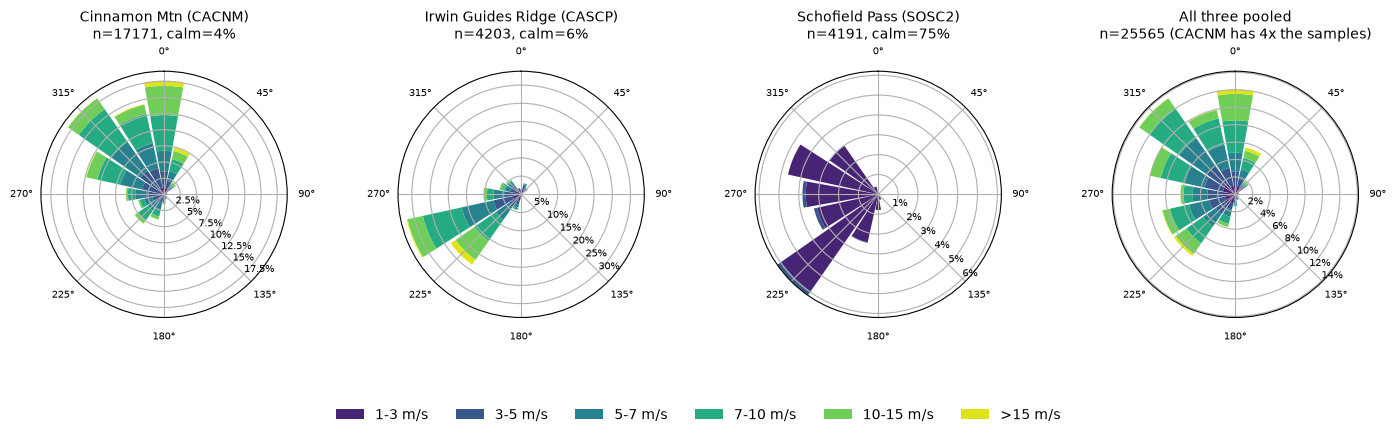

In [3]:
fig, axs = plt.subplots(1, 4, figsize=(17, 4.8), subplot_kw={'projection': 'polar'}, gridspec_kw={'wspace': 0.45})
for ax, (stid, g) in zip(axs, wind.groupby('station')):
    h = plot_wind_rose(ax, g.speed, g.direction, f'{names[stid]} ({stid})\nn={len(g)}, calm={np.mean(g.speed < 1):.0%}')
h = plot_wind_rose(axs[3], wind.speed, wind.direction, f'All three pooled\nn={len(wind)} (CACNM has 4x the samples)')
fig.legend(h, [x.get_label() for x in h], loc='lower center', ncol=6, frameon=False)
fig.savefig(project_root + '/outputs/figures/wind_roses_stations.png', dpi=200, bbox_inches='tight')
plt.show()

The same roses for only strong winds (7 m/s and above), roughly the blowing-snow threshold reported by Winstral et al.

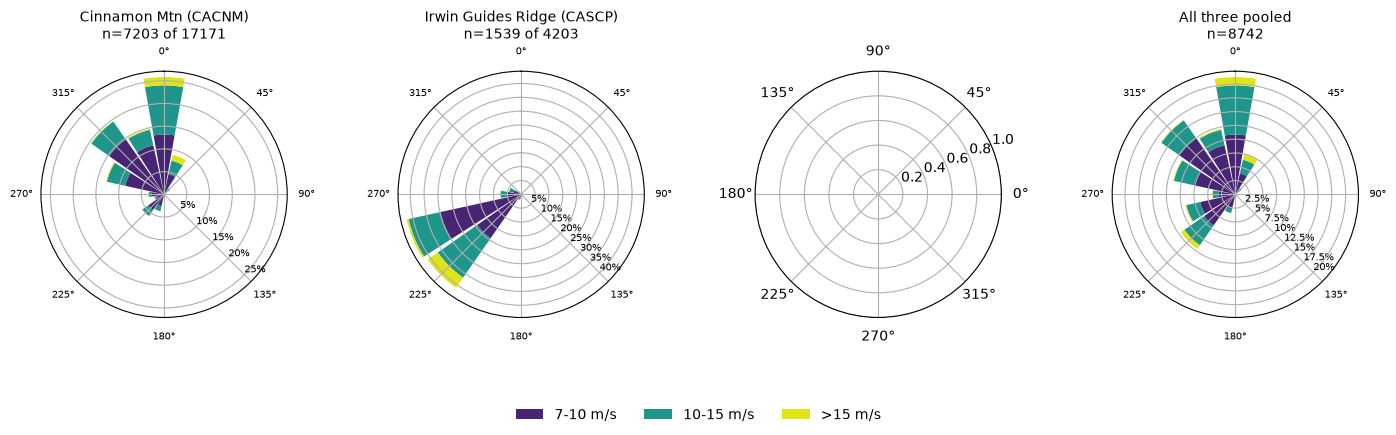

In [4]:
strong = wind[wind.speed >= 7]
fig, axs = plt.subplots(1, 4, figsize=(17, 4.8), subplot_kw={'projection': 'polar'}, gridspec_kw={'wspace': 0.45})
for ax, (stid, g) in zip(axs, strong.groupby('station')):
    h = plot_wind_rose(ax, g.speed, g.direction, f'{names[stid]} ({stid})\nn={len(g)} of {np.sum(wind.station == stid)}', speed_bins=(7, 10, 15, 100))
h = plot_wind_rose(axs[3], strong.speed, strong.direction, f'All three pooled\nn={len(strong)}', speed_bins=(7, 10, 15, 100))
fig.legend(h, [x.get_label() for x in h], loc='lower center', ncol=3, frameon=False)
fig.savefig(project_root + '/outputs/figures/wind_roses_stations_ge7ms.png', dpi=200, bbox_inches='tight')
plt.show()

Download a 10 m DEM for the test box in EPSG:32613. It is buffered by 600 m so cells at the box edge still see their full 500 m of upwind terrain.

In [5]:
BOX = {'x': (315960, 325000), 'y': (4307500, 4320500)}
DMAXS = (100, 300, 500)

dem_path = download_dem(BOX['x'], BOX['y'], 'EPSG:32613', 10, project_root + '/data/dem/dem_10m_testbox.tif', buffer=max(DMAXS) + 100)
dem = rxr.open_rasterio(dem_path, masked=True).squeeze(drop=True)
dem

<xarray.DataArray (y: 1420, x: 1024)> Size: 6MB
[1454080 values with dtype=float32]
Coordinates:
  * y            (y) float64 11kB 4.321e+06 4.321e+06 ... 4.307e+06 4.307e+06
  * x            (x) float64 8kB 3.154e+05 3.154e+05 ... 3.256e+05 3.256e+05
    spatial_ref  int64 8B 0
Attributes:
    units:                m
    vertical_datum:       NAVD88
    vertical_resolution:  0.001
    AREA_OR_POINT:        Area
    scale_factor:         1.0
    add_offset:           0.0
    long_name:            elevation

Compute Sx on the full buffered DEM, then crop to the test box. The wedge is the prevailing direction +/-30 deg with rays every 5 deg, as in the paper.

In [6]:
sx_all = compute_sx(dem, AZIMUTH, DMAXS, half_width=30, step=5)
sx_box = sx_all.sel(x=slice(*BOX['x']), y=slice(BOX['y'][1], BOX['y'][0]))
sx_box.attrs = {'source': 'Winstral et al. 2002 Eq. 1-2', 'wind_from_azimuth': AZIMUTH, 'dem': 'USGS 3DEP 10 m'}
sx_box

<xarray.Dataset> Size: 14MB
Dimensions:      (y: 1300, x: 904)
Coordinates:
  * y            (y) float64 10kB 4.32e+06 4.32e+06 ... 4.308e+06 4.308e+06
  * x            (x) float64 7kB 3.16e+05 3.16e+05 ... 3.25e+05 3.25e+05
    spatial_ref  int64 8B 0
Data variables:
    sx_100       (y, x) float32 5MB 3.13 2.554 2.193 1.972 ... 18.06 16.68 15.48
    sx_300       (y, x) float32 5MB 4.68 4.229 3.883 3.62 ... 24.14 23.54 23.04
    sx_500       (y, x) float32 5MB 4.758 4.325 4.034 ... 27.69 27.38 27.03
Attributes:
    source:             Winstral et al. 2002 Eq. 1-2
    wind_from_azimuth:  247
    dem:                USGS 3DEP 10 m

Check the maps. Positive Sx (sheltered, blue) should sit on lee slopes and negative Sx (exposed, red) on crests facing the wind, and the longer dmax should smooth the pattern.

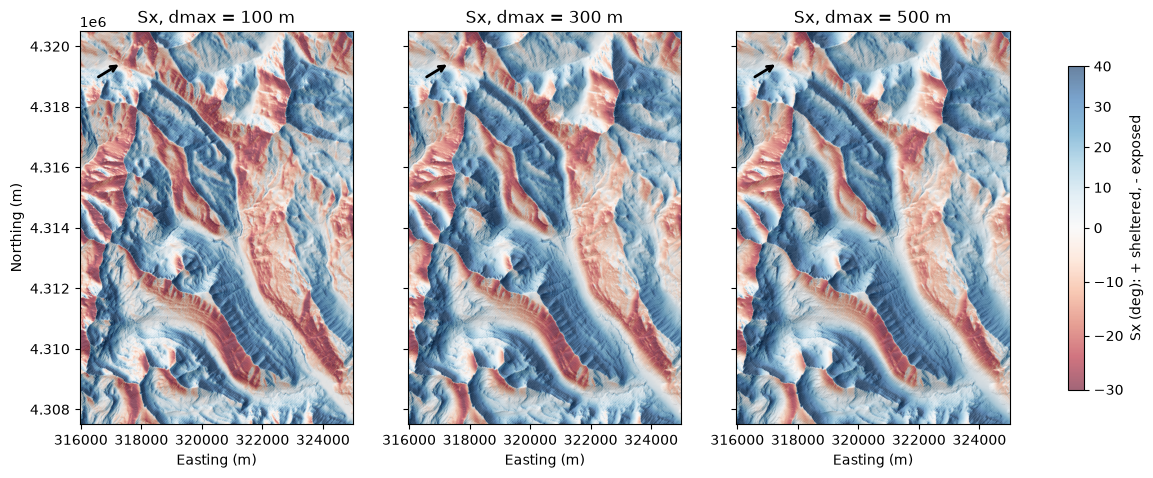

In [7]:
z = dem.sel(x=sx_box.x, y=sx_box.y).values
hill = LightSource(azdeg=315, altdeg=40).hillshade(z, vert_exag=2, dx=10, dy=10)
ext = [sx_box.x.min() - 5, sx_box.x.max() + 5, sx_box.y.min() - 5, sx_box.y.max() + 5]

fig, axs = plt.subplots(1, 3, figsize=(15, 7), sharey=True)
for ax, d in zip(axs, DMAXS):
    v = sx_box[f'sx_{d}'].values
    ax.imshow(hill, cmap='gray', extent=ext)
    im = ax.imshow(v, cmap='RdBu', norm=TwoSlopeNorm(0, -30, 40), alpha=0.6, extent=ext)
    ax.set_title(f'Sx, dmax = {d} m')
    ax.set_xlabel('Easting (m)')
    # arrow points where the wind blows TOWARD (opposite of the FROM azimuth)
    tail = np.array([0.06, 0.88])
    head = tail + 0.1 * np.array([-np.sin(np.deg2rad(AZIMUTH)), -np.cos(np.deg2rad(AZIMUTH))])
    ax.annotate('', xy=head, xytext=tail, xycoords='axes fraction', arrowprops=dict(arrowstyle='->', lw=2))
axs[0].set_ylabel('Northing (m)')
fig.colorbar(im, ax=axs, shrink=0.6, label='Sx (deg): + sheltered, - exposed')
fig.savefig(project_root + '/outputs/figures/sx_maps_testbox.png', dpi=200, bbox_inches='tight')
plt.show()

Save the layers as an Xarray Zarr and as one GeoTIFF per dmax for easy viewing in GIS.

In [8]:
out_dir = Path(project_root) / 'outputs'
sx_box.to_zarr(out_dir / 'wind_exposure_10m.zarr', mode='w')

(out_dir / 'wind_exposure_10m').mkdir(exist_ok=True)
for d in DMAXS:
    sx_box[f'sx_{d}'].rio.to_raster(out_dir / 'wind_exposure_10m' / f'sx_{d}.tif')

/Users/JULIALOBER/miniforge3/envs/coherence/lib/python3.11/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
